# Adding the baseline library for the function to work

In [ ]:
import sys
from pathlib import Path
import random
import pandas as pd

# 1. Cấu hình đường dẫn chuẩn cho ROOT và scripts/
cwd = Path.cwd()
SCRIPTS_DIR = cwd if cwd.name == "scripts" else cwd / "scripts"
ROOT_DIR = SCRIPTS_DIR.parent

for path in (str(ROOT_DIR), str(SCRIPTS_DIR)):
    if path not in sys.path:
        sys.path.insert(0, path)

# 2. Import các module cốt lõi
from curves.ecc import ECC, Point, FindOrder, sqrt_mod
from curves.exhaustive_search import exhaustive_search
from curves.bsgs import BSGS_ECC
from curves.pollard_rho import Pollard_Rho_ECC
from curves.pohlig_hellman import pohlig_hellman_ecc
from measure_harness import *
from fastecdsa.curve import P256

# 3. Sanity Check: Kiểm tra 4 thuật toán ECDLP trên đường cong nhỏ y^2 = x^3 + 2x + 3 (mod 97)
test_curve = ECC(2, 3, 97)
G_test = Point(test_curve, 3, 6)
n_test = FindOrder(G_test)
k_secret = 42 % n_test  # Phải nhỏ hơn bậc của điểm G (n_test = 5 -> k_secret = 2)
A_test = k_secret * G_test

assert exhaustive_search(A_test, G_test, n_test) == k_secret, "Lỗi ở Exhaustive Search"
assert BSGS_ECC(A_test, G_test) == k_secret, "Lỗi ở BSGS"
assert Pollard_Rho_ECC(A_test, G_test) == k_secret, "Lỗi ở Pollard's Rho"
assert pohlig_hellman_ecc(A_test, G_test) == k_secret, "Lỗi ở Pohlig-Hellman"

# 4. Sanity Check: Kiểm tra OpenSSL backend & measure_harness trên NIST P-256
p256_curve = ECC(P256.a, P256.b, P256.p)
assert p256_curve.uses_openssl is True, "OpenSSL backend chưa được kích hoạt cho P-256"

G_p256 = Point(p256_curve, P256.G.x, P256.G.y)
bench_test = measure(lambda: 123456789 * G_p256, repeat=3, memory=True)
assert bench_test["wall_time_ns"] > 0 and bench_test["memory_peak_kib"] is not None

print("All imports & sanity checks PASSED!")
print(f"  - Small curve order : {n_test} | Recovered k = {k_secret}")
print(f"  - NIST P-256 OpenSSL: Active ({bench_test['wall_time_ns'] / 1e3:.2f} µs/op)")

All imports & sanity checks PASSED!
  - Small curve order : 5 | Recovered k = 2
  - NIST P-256 OpenSSL: Active (41.23 µs/op)


# Testing baseline

In [ ]:


def find_valid_generator(curve: ECC, min_order_ratio: float = 0.25) -> Point:
    """Tìm điểm sinh G có bậc đủ lớn trên đường cong y^2 = x^3 + ax + b (mod p)."""
    p = curve.p
    for x in range(1, 1000):
        rhs = (x * x * x + curve.a * x + curve.b) % p
        y = sqrt_mod(rhs, p)
        if y is not None and curve.is_on_curve(x, y):
            pt = Point(curve, x, y)
            if FindOrder(pt) > max(10, int(p * min_order_ratio)):
                return pt
    raise RuntimeError(f"Could not find generator on curve mod {p}")


SMALL_PRIMES = [
    ("16-bit", 65521),
    ("20-bit", 1048573),
    ("24-bit", 16777213),
    ("28-bit", 268435399),
]

records = []
rng = random.Random(2026)

for label, p in SMALL_PRIMES:
    curve = ECC(2, 3, p)
    G = find_valid_generator(curve)
    order = FindOrder(G)
    k = rng.randint(2, order - 1)
    A = k * G

    algos = {
        # Cap Exhaustive Search at 21-bit so the notebook finishes quickly
        "Exhaustive": (lambda: exhaustive_search(A, G, order)) if order < (1 << 21) else None,
        "BSGS": lambda: BSGS_ECC(A, G),
        "Pollard_Rho": lambda: Pollard_Rho_ECC(A, G),
        "Pohlig_Hellman": lambda: pohlig_hellman_ecc(A, G),
    }

    for algo_name, fn in algos.items():
        if fn is None:
            continue
        stats = measure(fn, repeat=5, warmup=1, memory=True)
        assert stats["result"] == k, f"Mismatch on {algo_name} ({label})"
        records.append({
            "Curve": label,
            "Bits": order.bit_length(),
            "Order": order,
            "Algorithm": algo_name,
            "Wall_ms": stats["wall_time_ns"] / 1e6,
            "CPU_ms": stats["cpu_time_ns"] / 1e6,
            "Py_Heap_KiB": stats["memory_peak_kib"],
        })

print(f"{'Curve':<8} | {'Bits':<4} | {'Algorithm':<15} | {'Wall (ms)':>10} | {'CPU (ms)':>10} | {'Py Heap (KiB)':>13}")
print("-" * 74)
for r in records:
    print(
        f"{r['Curve']:<8} | {r['Bits']:<4} | {r['Algorithm']:<15} | "
        f"{r['Wall_ms']:>10.3f} | {r['CPU_ms']:>10.3f} | {r['Py_Heap_KiB']:>13.1f}"
    )

Curve    | Bits | Algorithm       |  Wall (ms) |   CPU (ms) | Py Heap (KiB)
--------------------------------------------------------------------------
16-bit   | 15   | Exhaustive      |      6.324 |      6.364 |           1.0
16-bit   | 15   | BSGS            |      0.489 |      0.489 |          26.3
16-bit   | 15   | Pollard_Rho     |      0.988 |      0.989 |           6.0
16-bit   | 15   | Pohlig_Hellman  |      0.625 |      0.626 |          14.1
20-bit   | 19   | Exhaustive      |    307.496 |    307.351 |           1.3
20-bit   | 19   | BSGS            |      2.016 |      2.016 |         111.0
20-bit   | 19   | Pollard_Rho     |      2.717 |      2.717 |          10.9
20-bit   | 19   | Pohlig_Hellman  |      1.201 |      1.204 |          42.3
24-bit   | 24   | BSGS            |      7.553 |      7.492 |         741.3
24-bit   | 24   | Pollard_Rho     |     54.465 |     54.006 |          20.7
24-bit   | 24   | Pohlig_Hellman  |      1.062 |      1.063 |          20.6
28-bit   | 28

In [27]:
# Choose a 40-bit prime p ≡ 3 (mod 4) where the curve order is smooth
smooth_curve = ECC(1, 7, 1099511627689)
G_smooth = find_valid_generator(smooth_curve)
n_smooth = FindOrder(G_smooth)

k_smooth = random.Random(99).randint(2, n_smooth - 1)
A_smooth = k_smooth * G_smooth

ph_stats = measure(lambda: pohlig_hellman_ecc(A_smooth, G_smooth), repeat=5, warmup=1, memory=True)
assert ph_stats["result"] == k_smooth

print(f"Smooth Curve Order : {n_smooth} ({n_smooth.bit_length()} bits)")
print(f"Pohlig-Hellman     : {ph_stats['wall_time_ns'] / 1e6:.3f} ms | Peak Py Heap: {ph_stats['memory_peak_kib']} KiB")

Smooth Curve Order : 1099512104067 (41 bits)
Pohlig-Hellman     : 122.377 ms | Peak Py Heap: 4213.4 KiB


In [28]:
print(f"{'Curve':<8} | {'Bits':<4} | {'BSGS Heap (KiB)':>16} | {'Pollard Rho Heap (KiB)':>22}")
print("-" * 60)

by_curve = {}
for r in records:
    if r["Algorithm"] in ("BSGS", "Pollard_Rho"):
        by_curve.setdefault((r["Curve"], r["Bits"]), {})[r["Algorithm"]] = r["Py_Heap_KiB"]

for (label, bits), mems in by_curve.items():
    bsgs_mem = f"{mems.get('BSGS', 0):.1f}"
    rho_mem = f"{mems.get('Pollard_Rho', 0):.1f}"
    print(f"{label:<8} | {bits:<4} | {bsgs_mem:>16} | {rho_mem:>22}")

Curve    | Bits |  BSGS Heap (KiB) | Pollard Rho Heap (KiB)
------------------------------------------------------------
16-bit   | 15   |             26.3 |                    6.0
20-bit   | 19   |            111.0 |                   10.9
24-bit   | 24   |            741.3 |                   20.7
28-bit   | 28   |           2989.2 |                   41.5


In [29]:
# 1. OpenSSL-accelerated P-256
curve_openssl = ECC(P256.a, P256.b, P256.p)
G_openssl = Point(curve_openssl, P256.G.x, P256.G.y)

# 2. Pure Python P-256 (disable OpenSSL hook for apples-to-apples comparison)
curve_py = ECC(P256.a, P256.b, P256.p)
curve_py._openssl_curve = None
G_py = Point(curve_py, P256.G.x, P256.G.y)

scalar_256 = random.Random(2026).getrandbits(256) % P256.q

res_ssl = measure(lambda: scalar_256 * G_openssl, repeat=50, warmup=5, memory=True)
res_py = measure(lambda: scalar_256 * G_py, repeat=50, warmup=5, memory=True)

assert res_ssl["result"] == res_py["result"]

speedup = res_py["wall_time_ns"] / res_ssl["wall_time_ns"]
print("NIST P-256 Scalar Multiplication (k * G):")
print(f"  - OpenSSL C Backend : {res_ssl['wall_time_ns'] / 1e3:8.2f} µs | Heap: {res_ssl['memory_peak_kib']} KiB")
print(f"  - Pure Python       : {res_py['wall_time_ns'] / 1e3:8.2f} µs | Heap: {res_py['memory_peak_kib']} KiB")
print(f"  => Speedup          : {speedup:.1f}x faster")

NIST P-256 Scalar Multiplication (k * G):
  - OpenSSL C Backend :    33.58 µs | Heap: 0.3 KiB
  - Pure Python       :  8270.38 µs | Heap: 1.0 KiB
  => Speedup          : 246.3x faster


In [ ]:
import csv
import platform
import subprocess
from contextlib import contextmanager



# Danh sách kích thước bit từ 12-bit đến 32-bit
BIT_SCALING_PRIMES = [
    (12, 4093),
    (14, 16381),
    (16, 65521),
    (18, 262139),
    (20, 1048573),
    (22, 4194301),
    (24, 16777213),
    (26, 67108859),
    (28, 268435399),
    (30, 1073741789),
    (32, 4294967291),
]

CPU_GHZ = get_cpu_freq_ghz()
DATA_DIR = ROOT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "D2_ecdlp_benchmarks.csv"

CSV_COLUMNS = [
    "target_bits",
    "prime_p",
    "subgroup_order",
    "order_bits",
    "algorithm",
    "secret_k",
    "wall_time_ns",
    "cpu_time_ns",
    "cpu_cycles",
    "cycles_source",
    "ec_add_ops",
    "ec_double_ops",
    "ec_mul_ops",
    "total_ec_ops",
    "memory_peak_kib",
    "rss_peak_kib",
]

rng_d2 = random.Random(2026)
d2_rows = []

for target_bits, p in BIT_SCALING_PRIMES:
    curve = ECC(2, 3, p)
    G = find_valid_generator(curve)
    order = FindOrder(G)
    k_secret = rng_d2.randint(2, order - 1)
    A = k_secret * G

    algo_suite = {
        "Exhaustive_Search": (lambda: exhaustive_search(A, G, order)) if order.bit_length() <= 20 else None,
        "BSGS": (lambda: BSGS_ECC(A, G)) if order.bit_length() <= 32 else None,
        "Pollard_Rho": (lambda: Pollard_Rho_ECC(A, G)) if order.bit_length() <= 32 else None,
        "Pohlig_Hellman": lambda: pohlig_hellman_ecc(A, G),
    }

    for algo_name, fn in algo_suite.items():
        if fn is None:
            continue

        # 1. Đo thời gian (wall/cpu) & bộ nhớ (memory) thuần túy
        repeats = 5 if order.bit_length() <= 24 else 3
        stats = measure(fn, repeat=repeats, warmup=1, memory=True)
        assert stats["result"] == k_secret, f"Sai nghiệm tại {algo_name} ({target_bits}-bit)"

        # 2. Đếm số lượng phép toán nhóm ở lượt chạy riêng
        random.seed(2026)
        with track_ecc_ops() as ops:
            fn()

        # 3. Thu thập cycles
        if stats.get("cpu_cycles") is not None:
            cycles = stats["cpu_cycles"]
            cycles_src = "rdtsc"
        else:
            cycles = int(stats["cpu_time_ns"] * CPU_GHZ)
            cycles_src = "estimated_from_cpu_ns"

        row = {
            "target_bits": target_bits,
            "prime_p": p,
            "subgroup_order": order,
            "order_bits": order.bit_length(),
            "algorithm": algo_name,
            "secret_k": k_secret,
            "wall_time_ns": stats["wall_time_ns"],
            "cpu_time_ns": stats["cpu_time_ns"],
            "cpu_cycles": cycles,
            "cycles_source": cycles_src,
            "ec_add_ops": ops.add_ops,
            "ec_double_ops": ops.double_ops,
            "ec_mul_ops": ops.mul_ops,
            "total_ec_ops": ops.total_ops,
            "memory_peak_kib": stats["memory_peak_kib"],
            "rss_peak_kib": stats.get("rss_peak_kib"),
        }
        d2_rows.append(row)
        print(
            f"[{target_bits:>2}-bit | {algo_name:<17}] "
            f"Wall: {row['wall_time_ns']/1e6:8.2f} ms | "
            f"Cycles: {row['cpu_cycles']:>12,} | "
            f"Ops: {row['total_ec_ops']:>8,} | "
            f"Mem: {row['memory_peak_kib']:>7.1f} KiB"
        )

with open(CSV_PATH, mode="w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=CSV_COLUMNS)
    writer.writeheader()
    writer.writerows(d2_rows)

print(f"\nExported {len(d2_rows)} rows (all 4 algorithms) to {CSV_PATH}")

[12-bit | Exhaustive_Search] Wall:     0.68 ms | Cycles:    1,245,931 | Ops:      244 | Mem:     0.4 KiB
[12-bit | BSGS             ] Wall:     0.23 ms | Cycles:      422,069 | Ops:      151 | Mem:     9.9 KiB
[12-bit | Pollard_Rho      ] Wall:     0.49 ms | Cycles:      891,034 | Ops:      406 | Mem:     3.5 KiB
[12-bit | Pohlig_Hellman   ] Wall:     0.33 ms | Cycles:      596,208 | Ops:      214 | Mem:     6.5 KiB
[14-bit | Exhaustive_Search] Wall:     3.89 ms | Cycles:    7,128,611 | Ops:    2,618 | Mem:     0.4 KiB
[14-bit | BSGS             ] Wall:     0.32 ms | Cycles:      583,656 | Ops:      209 | Mem:    20.4 KiB
[14-bit | Pollard_Rho      ] Wall:     1.21 ms | Cycles:    2,209,451 | Ops:      622 | Mem:     4.2 KiB
[14-bit | Pohlig_Hellman   ] Wall:     0.35 ms | Cycles:      641,365 | Ops:      244 | Mem:     4.1 KiB
[16-bit | Exhaustive_Search] Wall:     5.31 ms | Cycles:    9,743,043 | Ops:    3,364 | Mem:     0.9 KiB
[16-bit | BSGS             ] Wall:     0.49 ms | Cycles

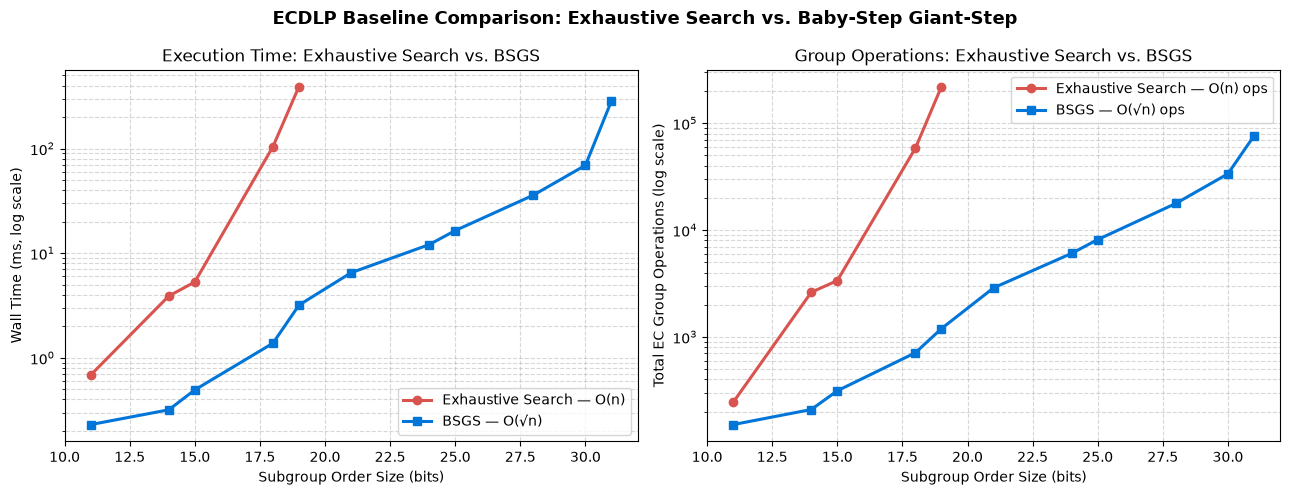

Saved chart to: /home/han-sui/ECC-Cryptanalysis/docs/charts/ecdlp_bsgs.png


In [31]:
import matplotlib.pyplot as plt

# Tạo thư mục docs/charts/ nếu chưa tồn tại
CHARTS_DIR = ROOT_DIR / "docs" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
OUT_PNG = CHARTS_DIR / "ecdlp_bsgs.png"

# Lọc dữ liệu 2 thuật toán Exhaustive_Search và BSGS từ d2_rows (Cell 6)
exh_rows = sorted([r for r in d2_rows if r["algorithm"] == "Exhaustive_Search"], key=lambda x: x["order_bits"])
bsgs_rows = sorted([r for r in d2_rows if r["algorithm"] == "BSGS"], key=lambda x: x["order_bits"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Biểu đồ trái: So sánh thời gian thực thi (Wall Time - Log Scale)
ax1.plot(
    [r["order_bits"] for r in exh_rows],
    [r["wall_time_ns"] / 1e6 for r in exh_rows],
    marker="o",
    linewidth=2.2,
    color="#d9534f",
    label="Exhaustive Search — O(n)",
)
ax1.plot(
    [r["order_bits"] for r in bsgs_rows],
    [r["wall_time_ns"] / 1e6 for r in bsgs_rows],
    marker="s",
    linewidth=2.2,
    color="#0275d8",
    label="BSGS — O(√n)",
)
ax1.set_yscale("log")
ax1.set_title("Execution Time: Exhaustive Search vs. BSGS")
ax1.set_xlabel("Subgroup Order Size (bits)")
ax1.set_ylabel("Wall Time (ms, log scale)")
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend()

# 2. Biểu đồ phải: So sánh số phép toán nhóm ECC (Total EC Ops - Log Scale)
ax2.plot(
    [r["order_bits"] for r in exh_rows],
    [r["total_ec_ops"] for r in exh_rows],
    marker="o",
    linewidth=2.2,
    color="#d9534f",
    label="Exhaustive Search — O(n) ops",
)
ax2.plot(
    [r["order_bits"] for r in bsgs_rows],
    [r["total_ec_ops"] for r in bsgs_rows],
    marker="s",
    linewidth=2.2,
    color="#0275d8",
    label="BSGS — O(√n) ops",
)
ax2.set_yscale("log")
ax2.set_title("Group Operations: Exhaustive Search vs. BSGS")
ax2.set_xlabel("Subgroup Order Size (bits)")
ax2.set_ylabel("Total EC Group Operations (log scale)")
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.legend()

plt.suptitle("ECDLP Baseline Comparison: Exhaustive Search vs. Baby-Step Giant-Step", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved chart to: {OUT_PNG}")

# Further discussion

In [32]:
# Minh họa lỗ hổng Timing Side-Channel trên thuật toán Double-and-Add thuần túy
curve_sc = ECC(P256.a, P256.b, P256.p)
curve_sc._openssl_curve = None  # Dùng thuật toán Double-and-Add Python thuần
G_sc = Point(curve_sc, P256.G.x, P256.G.y)

k_sparse = (1 << 255) + 1          # Trọng số Hamming = 2 (chỉ có 2 bit 1 -> ít phép cộng điểm)
k_dense = (1 << 256) - 1           # Trọng số Hamming = 256 (toàn bit 1 -> tối đa phép cộng điểm)

t_sparse = measure(lambda: k_sparse * G_sc, repeat=30, warmup=5)
t_dense = measure(lambda: k_dense * G_sc, repeat=30, warmup=5)

print("Timing Side-Channel Leakage (Pure Python Double-and-Add):")
print(f"  - Sparse key (2 bits = 1)   : {t_sparse['wall_time_ns'] / 1e3:8.2f} µs")
print(f"  - Dense key  (256 bits = 1) : {t_dense['wall_time_ns'] / 1e3:8.2f} µs")
print(f"  => Time difference          : {(t_dense['wall_time_ns'] - t_sparse['wall_time_ns']) / 1e3:8.2f} µs (leaks Hamming weight!)")

Timing Side-Channel Leakage (Pure Python Double-and-Add):
  - Sparse key (2 bits = 1)   :  5132.44 µs
  - Dense key  (256 bits = 1) :  8979.91 µs
  => Time difference          :  3847.47 µs (leaks Hamming weight!)
